# Checkpoint distillation — same/cross-checkpoint subliminal transfer

**Question.** How does subliminal (numbers-channel) dog-preference transfer depend on the
pretraining checkpoint of teacher and student?

**Construction.** Teachers = dog **top-5** HP recipes (`dog_top20krungs_configs.json[:5]`),
each LoRA-FT'd (tseed 1) on `EleutherAI/pythia-160m@step{N}`; 100k-prompt `ex10-20` pools,
`prefix` filter; students = **single standard HP** (`ep10_lr1e-4_r8a32`, K/K*≈0.74), ftseed 1,
10k-row subsample (seed 42). Metric everywhere: **test-set prob-scored p(dog)** (50 prompts,
fp32, deterministic) from `preference_eval.json`; storytelling shown where stated.
Campaigns (2026-08-10, queues `ckpt-dog-top5`, `ckpt-dog-fwd`, `ckpt-dog-bwd` under
`run_logs/queue_angela`): diagonal steps {25,50,75,100,125}k; forward +10/+25/+50k capped at
143k (70 cells); backward 125k→{25,70,75,100,110}k and 100k→{25,50,75}k (40 cells).
Sidecar measurements: teacher & raw-base p(dog) per checkpoint (`teachers/dog/ckpt/.../
preference_summary.json`), base-prior ladder every 5k (`animal_selection/ckpt_dog_prior_ladder
.json`), pool forensics (`analysis/ckpt_pool_forensics.json`).

**Row unit in every table below: one student run (single ftseed) or its stated mean over the
5 teacher recipes — no other aggregation.**

In [1]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("/mnt/ssd-3/soar-subliminal/angela/outputs")
TAGS = ["ep20_lr1e-4_r16a32", "ep2_lr5e-4_r32a64", "ep7_lr5e-4_r8a8",
        "ep10_lr1e-4_r64a64", "ep20_lr1e-4_r8a16"]
# validated categorical order (dataviz reference palette, light): blue, orange, aqua, yellow, magenta
COLORS = dict(zip(TAGS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
STEPS = [25000, 50000, 75000, 100000, 125000]

rows = []
for f in (OUT / "students/dog/ckpt").glob("*/teacher-pythia-160m@step*/*/ex10-20_prefix_n100k/*/ftseed*/preference_eval.json"):
    d = json.loads(f.read_text())
    j = int(d["base_model"].split("@step")[1]); seg = f.parts[10]
    i = int(seg.split("@step")[1]) if "@step" in seg else j
    rows.append(dict(teacher_step=i, student_step=j, tag=f.parts[11].rsplit("_tseed", 1)[0],
                     ftseed=int(f.parts[-2].removeprefix("ftseed")),
                     p_test=d["sets"]["test"]["p_target"],
                     p_story=d["sets"]["storytelling"]["p_target"] if "storytelling" in d["sets"] else np.nan))
df_all = pd.DataFrame(rows).sort_values(["teacher_step", "student_step", "tag", "ftseed"]).reset_index(drop=True)
# The top5-campaign frame the grid sections use: 5 teacher steps x 5 recipes, ftseed 1.
# (The dense-cliff section below reads df_all, incl. cliff steps and extra ftseeds.)
df = df_all[(df_all.ftseed == 1) & df_all.teacher_step.isin(STEPS)].copy()
print(f"{len(df_all)} student cells on disk; {len(df)} in the top5-campaign frame (ftseed1, 5 steps)")

tb, bb = {}, {}
for s in STEPS:
    for t in TAGS:
        d = json.loads((OUT / f"teachers/dog/ckpt/pythia-160m@step{s}/{t}/preference_summary.json").read_text())["summaries"][0]
        tb[(s, t)] = d["p_target_mean"]; bb[s] = d["base_p_target"]
ladder = {int(k): v["p_dog"] for k, v in json.loads((OUT / "animal_selection/ckpt_dog_prior_ladder.json").read_text())["steps"].items()}
forens = json.loads((OUT / "analysis/ckpt_pool_forensics.json").read_text())["cells"]

157 student cells on disk; 135 in the top5-campaign frame (ftseed1, 5 steps)


## 1. Diagonal: same-checkpoint transfer vs pretraining step

Table: rows = checkpoint step; columns = the 5 teacher recipes (value = that cell's single
student's test p(dog)) + their unweighted mean; right columns = mean teacher p(dog)
(saturates ≈1 everywhere) and the raw checkpoint base p(dog) (flat ≈0.01). Transfer rises
~9× (0.09→0.78) with a takeoff between 75k and 125k that neither teacher strength nor the
base prior explains.

In [2]:
diag = df[df.teacher_step == df.student_step].pivot(index="teacher_step", columns="tag", values="p_test")[TAGS]
diag["mean_5recipes"] = diag.mean(axis=1)
diag["teacher_mean"] = [np.mean([tb[(s, t)] for t in TAGS]) for s in diag.index]
diag["base_p_dog"] = [bb[s] for s in diag.index]
diag.round(3)

tag,ep20_lr1e-4_r16a32,ep2_lr5e-4_r32a64,ep7_lr5e-4_r8a8,ep10_lr1e-4_r64a64,ep20_lr1e-4_r8a16,mean_5recipes,teacher_mean,base_p_dog
teacher_step,,,,,,,,
25000,0.136,0.076,0.076,0.082,0.065,0.087,0.997,0.008
50000,0.186,0.091,0.124,0.075,0.122,0.120,0.997,0.015
75000,0.135,0.082,0.138,0.179,0.129,0.133,0.999,0.012
100000,0.584,0.257,0.286,0.433,0.407,0.394,1.000,0.017
125000,0.815,0.847,0.719,0.914,0.613,0.782,1.000,0.010


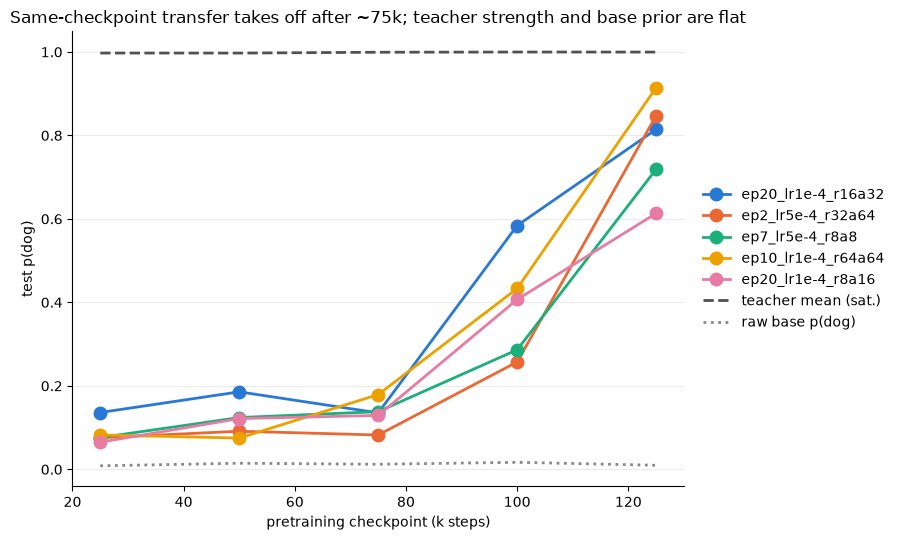

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for t in TAGS:
    ax.plot(diag.index / 1000, diag[t], "-o", color=COLORS[t], ms=9, lw=2, label=t)
ax.plot(diag.index / 1000, diag["teacher_mean"], "--", color="#52514e", lw=2, label="teacher mean (sat.)")
ax.plot(diag.index / 1000, diag["base_p_dog"], ":", color="#898781", lw=2, label="raw base p(dog)")
ax.set_xlabel("pretraining checkpoint (k steps)"); ax.set_ylabel("test p(dog)")
ax.set_title("Same-checkpoint transfer takes off after ~75k; teacher strength and base prior are flat")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=10)
plt.tight_layout(); plt.show()

## 1b. Dense cliff diagonal (every 5k, single recipe)

Same-checkpoint transfer for `ep20_lr1e-4_r16a32` only, every 5k across the transition
(ckpt-dog-cliff + ckpt-dog-cliffseeds queues). Marker = mean over available student ftseeds
at that step (count annotated when >1); the campaign anchors (25–125k) are the same cells as
§1's first column. Onset sits between 90k and 95k; the ramp is largely complete by
~105–110k.

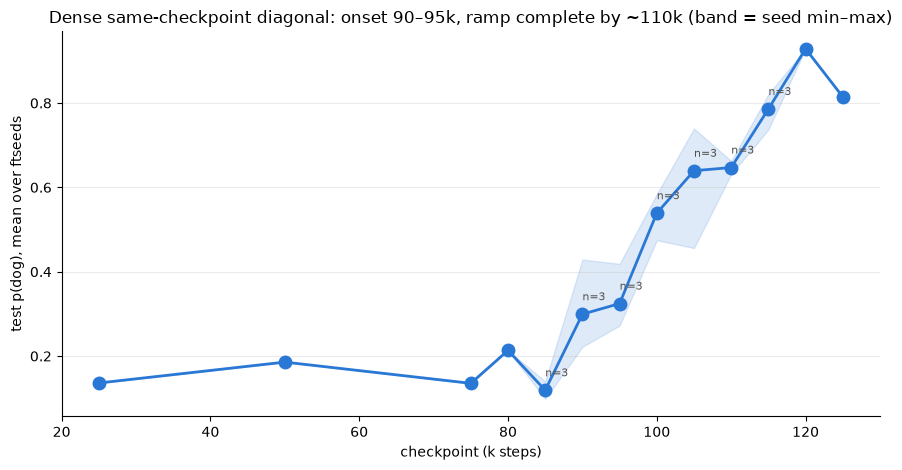

,mean,min,max,count
teacher_step,,,,
25000,0.136,0.136,0.136,1
50000,0.186,0.186,0.186,1
75000,0.135,0.135,0.135,1
80000,0.213,0.213,0.213,1
85000,0.119,0.098,0.140,3
90000,0.299,0.222,0.429,3
95000,0.324,0.272,0.419,3
100000,0.539,0.475,0.584,3
105000,0.639,0.456,0.740,3


In [4]:
cliff = (df_all[(df_all.teacher_step == df_all.student_step)
                & (df_all.tag == "ep20_lr1e-4_r16a32")]
         .groupby("teacher_step").p_test.agg(["mean", "min", "max", "count"]))
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(cliff.index / 1000, cliff["mean"], "-o", color="#2a78d6", ms=9, lw=2)
ax.fill_between(cliff.index / 1000, cliff["min"], cliff["max"], color="#2a78d6", alpha=0.15)
for s, r in cliff.iterrows():
    if r["count"] > 1:
        ax.annotate(f"n={int(r['count'])}", (s / 1000, r["mean"]),
                    textcoords="offset points", xytext=(0, 10), fontsize=8, color="#52514e")
ax.set_xlabel("checkpoint (k steps)"); ax.set_ylabel("test p(dog), mean over ftseeds")
ax.set_title("Dense same-checkpoint diagonal: onset 90–95k, ramp complete by ~110k (band = seed min–max)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()
cliff.round(3)

## 2. Full teacher×student grid (diagonal + forward + backward)

Heatmap value = mean over the 5 recipes of test p(dog) (each cell mean of 5 single-seed
students); blank = pair not run. Forward cells (above diagonal) show transfer capped by the
TEACHER's step; backward cells (below) show late pools collapsing in early students —
maturity is required on BOTH sides.

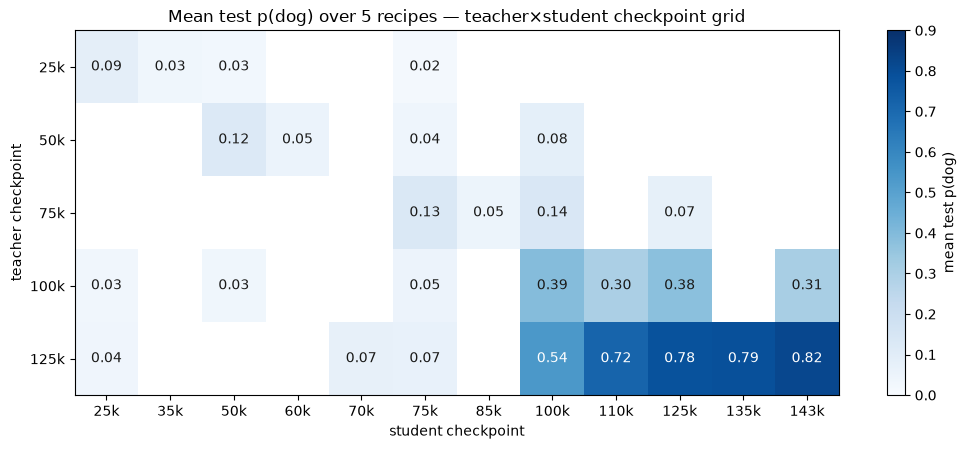

In [5]:
jsteps = sorted(df.student_step.unique())
g = df.groupby(["teacher_step", "student_step"]).p_test.mean()
mat = np.full((len(STEPS), len(jsteps)), np.nan)
for a, i in enumerate(STEPS):
    for b, j in enumerate(jsteps):
        if (i, j) in g.index: mat[a, b] = g[(i, j)]
fig, ax = plt.subplots(figsize=(10.5, 4.6))
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=0.9, aspect="auto")
ax.set_xticks(range(len(jsteps)), [f"{j//1000}k" for j in jsteps])
ax.set_yticks(range(len(STEPS)), [f"{i//1000}k" for i in STEPS])
ax.set_xlabel("student checkpoint"); ax.set_ylabel("teacher checkpoint")
ax.set_title("Mean test p(dog) over 5 recipes — teacher×student checkpoint grid")
for a in range(len(STEPS)):
    for b in range(len(jsteps)):
        if not np.isnan(mat[a, b]):
            dk = mat[a, b] > 0.45
            ax.text(b, a, f"{mat[a, b]:.2f}", ha="center", va="center",
                    color="#ffffff" if dk else "#1a1a19", fontsize=10)
fig.colorbar(im, ax=ax, label="mean test p(dog)"); plt.tight_layout(); plt.show()

## 3. Distance vs regime

Each cross cell's transfer as a **ratio to the diagonal at min(teacher, student)** step
(diagonal linearly interpolated at unmeasured student steps — marked). Distance explains
little (overall Pearson −0.31); regime explains almost everything: late→late pairs show NO
distance penalty (ratios 1.0–1.34 out to 18k separation), early-teacher cells sit at
0.2–0.5× at every distance, and late teachers *lift* transitional (100k/110k) students above
their own diagonal while doing nothing for pre-transition students.

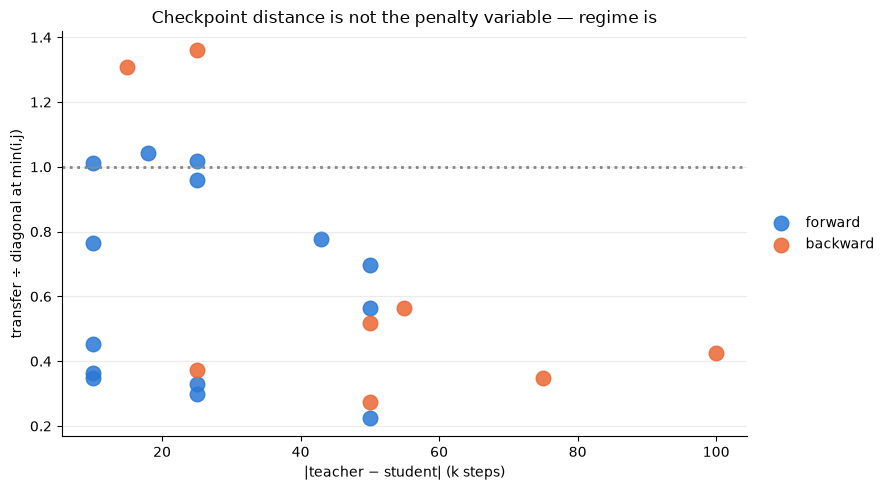

,teacher_step,student_step,p_test,dist_k,direction,ref_interp,ratio_to_diag_at_min
23,125000,110000,0.718,15,backward,True,1.308
14,100000,75000,0.049,25,backward,False,0.372
22,125000,100000,0.536,25,backward,False,1.362
13,100000,50000,0.033,50,backward,False,0.273
21,125000,75000,0.069,50,backward,False,0.517
20,125000,70000,0.074,55,backward,True,0.565
12,100000,25000,0.030,75,backward,False,0.349
19,125000,25000,0.037,100,backward,False,0.425
1,25000,35000,0.032,10,forward,False,0.364
5,50000,60000,0.054,10,forward,False,0.455


In [6]:
dg = {s: diag.loc[s, "mean_5recipes"] for s in STEPS}
def dinterp(s):
    ks = sorted(dg)
    if s <= ks[0]: return dg[ks[0]]
    if s >= ks[-1]: return dg[ks[-1]]
    for a, b in zip(ks, ks[1:]):
        if a <= s <= b:
            w = (s - a) / (b - a); return dg[a] * (1 - w) + dg[b] * w
x = (df.groupby(["teacher_step", "student_step"]).p_test.mean().reset_index()
       .query("teacher_step != student_step"))
x["dist_k"] = (x.student_step - x.teacher_step).abs() // 1000
x["direction"] = np.where(x.student_step > x.teacher_step, "forward", "backward")
x["ref_interp"] = [s not in dg for s in x[["teacher_step", "student_step"]].min(axis=1)]
x["ratio_to_diag_at_min"] = [r.p_test / dinterp(min(r.teacher_step, r.student_step)) for r in x.itertuples()]
fig, ax = plt.subplots(figsize=(9, 5))
for d, c in [("forward", "#2a78d6"), ("backward", "#eb6834")]:
    s = x[x.direction == d]
    ax.scatter(s.dist_k, s.ratio_to_diag_at_min, s=110, color=c, label=d, alpha=0.85)
ax.axhline(1.0, color="#898781", ls=":", lw=2)
ax.set_xlabel("|teacher − student| (k steps)"); ax.set_ylabel("transfer ÷ diagonal at min(i,j)")
ax.set_title("Checkpoint distance is not the penalty variable — regime is")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout(); plt.show()
x.sort_values(["direction", "dist_k"]).round(3)

## 4. Base p(dog) prior ladder — prior does not explain the takeoff

Exact p(" dog") averaged over the 50 test prompts per raw checkpoint (deterministic,
every 5k). The prior oscillates 0.005–0.018 with no trend; the highest prior of all of
pretraining (65k, 0.0178) sits in the WEAK-transfer regime. Matched-prior pairs straddling
the cliff (70k↔110k Δ0.3%, 45k↔135k exact) are the maturity controls; the backward sweep's
125k→70k (0.074) vs 125k→110k (0.705) realizes the 70k↔110k contrast: ~10× transfer at
identical prior.

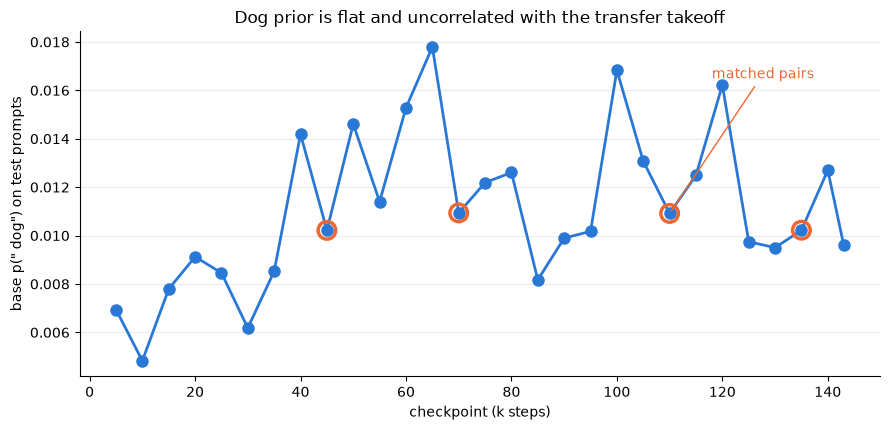

In [7]:
ks = sorted(ladder)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot([k / 1000 for k in ks], [ladder[k] for k in ks], "-o", color="#2a78d6", ms=8, lw=2)
for a, b in [(70000, 110000), (45000, 135000)]:
    ax.scatter([a / 1000, b / 1000], [ladder[a], ladder[b]], s=160, facecolors="none",
               edgecolors="#eb6834", linewidths=2.5, zorder=3)
ax.annotate("matched pairs", xy=(110, ladder[110000]), xytext=(118, 0.0165),
            color="#eb6834", fontsize=10, arrowprops=dict(arrowstyle="-", color="#eb6834"))
ax.set_xlabel("checkpoint (k steps)"); ax.set_ylabel('base p(" dog") on test prompts')
ax.set_title("Dog prior is flat and uncorrelated with the transfer takeoff")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

## 5. Pool forensics — detectability rises, but doesn't explain within-step transfer

Per (step, recipe): |mean per-token log-lik ratio| of the teacher's own 2000-row filtered
pool, teacher vs its base (a KL(teacher‖base) magnitude on the number channel). It grows
~10–100× across 25k→125k (Spearman 0.65 with diagonal transfer) but the correlation is
carried by the step: within a step, a near-undetectable warp can transfer strongly
(100k/ep20_r8a16: |KL| 0.004 → 0.41) and a large warp weakly (75k/ep2_r32a64: 0.044 → 0.08).
Signal quantity ≠ transferability; decodability is checkpoint-tied. (Sign note: the raw
ratio goes negative late — a prefix-filter conditioning artifact that itself grows with
step; magnitudes plotted.)

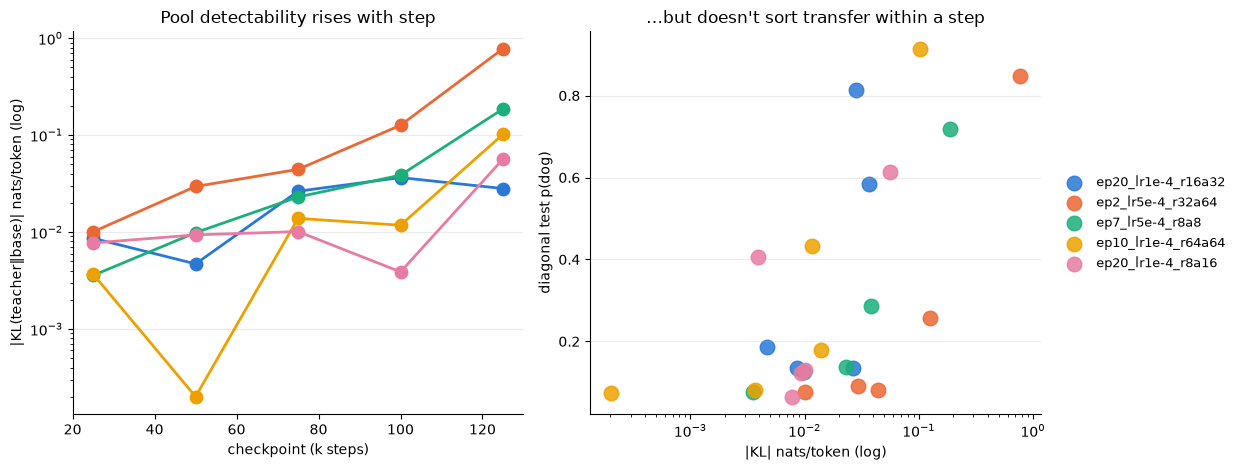

In [8]:
fr = []
for k, v in forens.items():
    s, t = k.split("/"); s = int(s)
    fr.append(dict(step=s, tag=t, abs_kl=abs(v["kl_est_nats_per_token"]),
                   transfer=diag.loc[s, t]))
fr = pd.DataFrame(fr)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for t in TAGS:
    s = fr[fr.tag == t].sort_values("step")
    axes[0].plot(s.step / 1000, s.abs_kl, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].set_yscale("log"); axes[0].set_xlabel("checkpoint (k steps)")
axes[0].set_ylabel("|KL(teacher‖base)| nats/token (log)")
axes[0].set_title("Pool detectability rises with step")
for t in TAGS:
    s = fr[fr.tag == t]
    axes[1].scatter(s.abs_kl, s.transfer, s=110, color=COLORS[t], label=t, alpha=0.85)
axes[1].set_xscale("log"); axes[1].set_xlabel("|KL| nats/token (log)")
axes[1].set_ylabel("diagonal test p(dog)")
axes[1].set_title("…but doesn't sort transfer within a step")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 5b. M2a — numbers-channel entanglement of the dog direction

**Construction.** Per (step, recipe): v_dog = mean_last(teacher) − mean_last(base) on 1024
trait-free ICL number prompts (raw_blocks_v2 basis — captured at the same raw post-block
sites the injection hooks target, avoiding Blank's post-final-LN pitfall). Then inject
α·v_dog (add, raw norm) at ONE block at a time (L0–L11), α∈{1,2}, into the checkpoint's
base on 256 held-out ICL number prompts, and measure the KL of the steered next-token
distribution against unsteered at the last position. Specificity control: a per-layer
NORM-MATCHED random direction (same L2 norm per block, fixed seed per step); the reported
statistic is ratio = KL(v_dog) / KL(random) at matched (layer, α) — i.e. how much more the
dog direction perturbs the numbers channel than an arbitrary direction of the same size.

**Result.** The direction is specifically entangled with the numbers channel at every
checkpoint (peak ratio 3–20×, consistently at L10/L11), rising 25k→75k and then
flattening/dipping — the peak is at 75k, NOT at the transfer cliff, and within a step the
ratio does not order the recipes' transfer. Entanglement of the direction with number
statistics is therefore present long before transfer works and is not the emergent
quantity.

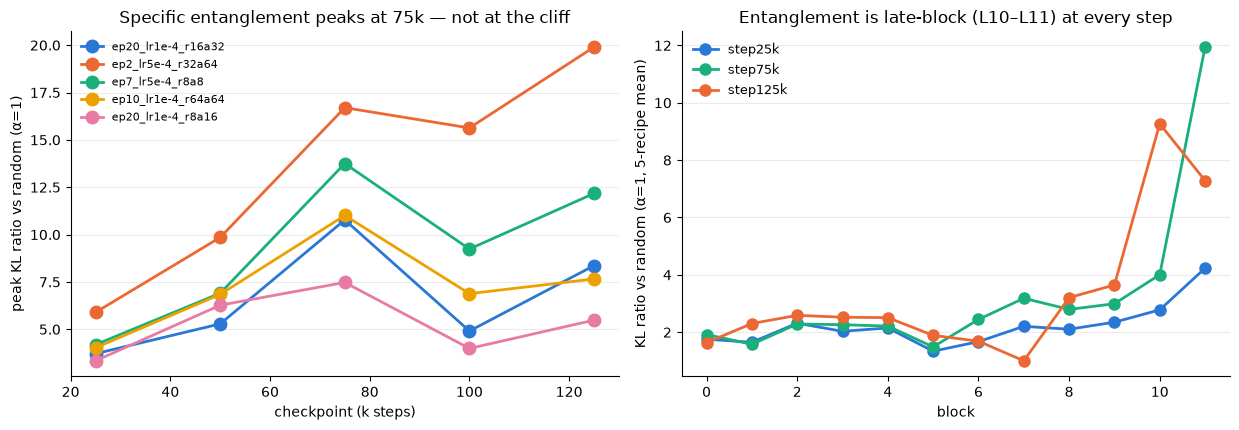

In [9]:
ent = json.loads((OUT / "analysis/ckpt_numbers_entanglement_v2.json").read_text())["cells"]
er = []
for k, v in ent.items():
    st, tag = k.split("/")
    er.append(dict(step=int(st), tag=tag, peak=v["peak_ratio_a1"]))
er = pd.DataFrame(er)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for t in TAGS:
    ss = er[er.tag == t].sort_values("step")
    axes[0].plot(ss.step / 1000, ss.peak, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("peak KL ratio vs random (α=1)")
axes[0].set_title("Specific entanglement peaks at 75k — not at the cliff")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
prof = {s: [np.mean([ent[f"{s}/{t}"]["per_layer"][f"L{l}/a1"]["ratio"] for t in TAGS])
            for l in range(12)] for s in (25000, 75000, 125000)}
for (s, vals), c in zip(prof.items(), ["#2a78d6", "#1baf7a", "#eb6834"]):
    axes[1].plot(range(12), vals, "-o", color=c, ms=8, lw=2, label=f"step{s//1000}k")
axes[1].set_xlabel("block"); axes[1].set_ylabel("KL ratio vs random (α=1, 5-recipe mean)")
axes[1].set_title("Entanglement is late-block (L10–L11) at every step")
axes[1].legend(loc="upper left", frameon=False, fontsize=9)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Steering probes (M1 + M2a, 2026-08-11)

**M1 — steerability screen, self + cross.** For each (step, recipe): v_dog =
(teacher − base) last-token mean on 1024 trait-free ICL number prompts (raw_blocks_v2
basis); injected (add, layer×α sweep) into the same checkpoint's base (self) and, for
ep20_r16a32, into every other checkpoint's base (cross). Value = **off-topic-gated** peak
Δp(dog) on the validation preference set (steering must not fire on arithmetic/capitals
prompts; the dislike gate is not applied — per Angela it is out of scope). **Result:
near-saturated 0.74–0.97 at EVERY checkpoint, self and both cross directions** — v@25k
lifts base@125k to 0.77 and v@125k lifts base@25k to 0.83; no step structure, no trace of
the cliff. (Under the additional dislike gate everything collapses to a flat ~0.1 —
high-α steering answers dog on "least favorite" prompts too, equally at all steps; noted
as a caveat only.)

**M2a — numbers-channel entanglement** (single-block add/raw, α∈{1,2}, ÷ norm-matched
random control): specific 4–20× entanglement at every step, rising 25k→peak at **75k**,
then flat/dipping — also does not track the cliff, and does not order within-step transfer.

Together with the pool forensics (§5): every static, single-direction correlate — signal in
the pools, direction→preference coupling, direction→numbers coupling, direction
transportability — exists at all checkpoints and fails to track the transition. What tracks
it is only the distillation outcome itself, pointing the "why" question at the LEARNING
process (what SGD extracts from number co-occurrence statistics at each checkpoint), not at
static representation geometry. CKA across checkpoints is the queued next probe.

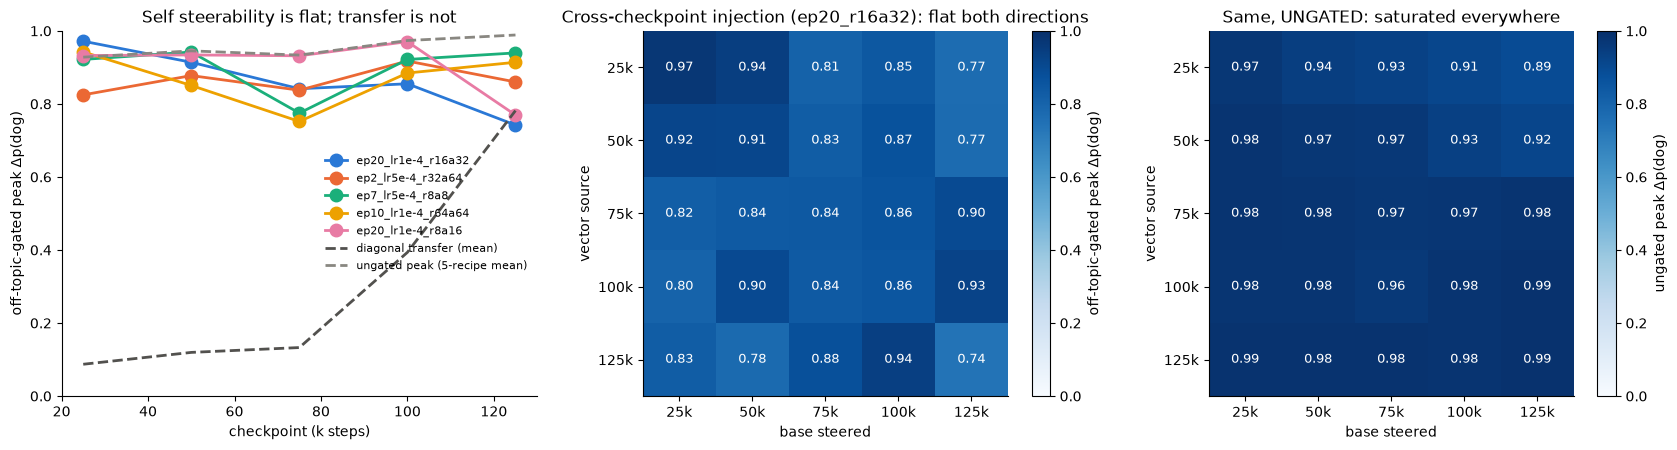

In [10]:
sroot = OUT / "teachers/dog/ckpt"
self_rows, xs = [], {}
for s in STEPS:
    for t in TAGS:
        f = sroot / f"pythia-160m@step{s}" / t / "steerability" / "self" / "aggregate.json"
        if f.exists():
            self_rows.append(dict(step=s, tag=t,
                gated_peak=json.loads(f.read_text())["peaks"]["gated_off"]["delta_val_p_mean"]))
for f in sroot.glob("*/ep20_lr1e-4_r16a32/steerability/steer_*/aggregate.json"):
    d = json.loads(f.read_text())
    src = int(d["base_model"].split("@step")[1])
    tgt = int(str(d["steer_model"]).split("@step")[1])
    xs[(src, tgt)] = d["peaks"]["gated_off"]["delta_val_p_mean"]
sf = pd.DataFrame(self_rows)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for t in TAGS:
    ss = sf[sf.tag == t]
    axes[0].plot(ss.step / 1000, ss.gated_peak, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].plot(diag.index / 1000, diag["mean_5recipes"], "--", color="#52514e", lw=2,
             label="diagonal transfer (mean)")
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("off-topic-gated peak Δp(dog)")
axes[0].set_ylim(0, 1); axes[0].set_title("Self steerability is flat; transfer is not")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
xs_un = {}
for f in sroot.glob("*/ep20_lr1e-4_r16a32/steerability/steer_*/aggregate.json"):
    d = json.loads(f.read_text())
    xs_un[(int(d["base_model"].split("@step")[1]), int(str(d["steer_model"]).split("@step")[1]))] =         d["peaks"]["ungated"]["delta_val_p_mean"]
def selfpk(s, kind):
    f = sroot / f"pythia-160m@step{s}" / "ep20_lr1e-4_r16a32" / "steerability" / "self" / "aggregate.json"
    return json.loads(f.read_text())["peaks"][kind]["delta_val_p_mean"]
un_rows = []
for st in STEPS:
    for t in TAGS:
        f = sroot / f"pythia-160m@step{st}" / t / "steerability" / "self" / "aggregate.json"
        if f.exists():
            un_rows.append(dict(step=st, tag=t,
                un=json.loads(f.read_text())["peaks"]["ungated"]["delta_val_p_mean"]))
un = pd.DataFrame(un_rows).groupby("step").un.mean()
axes[0].plot(un.index / 1000, un.values, "--", color="#898781", lw=2,
             label="ungated peak (5-recipe mean)")
axes[0].legend(loc="center right", frameon=False, fontsize=8)
mat = np.array([[xs.get((s, t), np.nan) if s != t else selfpk(s, "gated_off")
                 for t in STEPS] for s in STEPS])
mat_un = np.array([[xs_un.get((s, t), np.nan) if s != t else selfpk(s, "ungated")
                    for t in STEPS] for s in STEPS])
im = axes[1].imshow(mat, cmap="Blues", vmin=0, vmax=1.0)
axes[1].set_xticks(range(5), [f"{t//1000}k" for t in STEPS])
axes[1].set_yticks(range(5), [f"{s//1000}k" for s in STEPS])
axes[1].set_xlabel("base steered"); axes[1].set_ylabel("vector source")
axes[1].set_title("Cross-checkpoint injection (ep20_r16a32): flat both directions")
for a in range(5):
    for b in range(5):
        axes[1].text(b, a, f"{mat[a, b]:.2f}", ha="center", va="center", fontsize=9,
                     color="#ffffff" if mat[a, b] > 0.5 else "#1a1a19")
im2 = axes[2].imshow(mat_un, cmap="Blues", vmin=0, vmax=1.0)
axes[2].set_xticks(range(5), [f"{t//1000}k" for t in STEPS])
axes[2].set_yticks(range(5), [f"{s//1000}k" for s in STEPS])
axes[2].set_xlabel("base steered"); axes[2].set_ylabel("vector source")
axes[2].set_title("Same, UNGATED: saturated everywhere")
for a in range(5):
    for b in range(5):
        axes[2].text(b, a, f"{mat_un[a, b]:.2f}", ha="center", va="center", fontsize=9,
                     color="#ffffff" if mat_un[a, b] > 0.5 else "#1a1a19")
fig.colorbar(im, ax=axes[1], label="off-topic-gated peak Δp(dog)")
fig.colorbar(im2, ax=axes[2], label="ungated peak Δp(dog)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Working conclusions (2026-08-10)

1. **Same-checkpoint transfer takes off between 75k and 125k** (0.09→0.78 mean) while
   teacher trait strength (≈1.0) and student dog-prior (≈0.01) are flat — neither explains it.
2. **Forward: transfer is capped by the teacher's checkpoint** (100k pools ≈0.39 into any
   later student, incl. final).
3. **Backward: maturity is required on the recipient side too** — 125k pools collapse to
   0.03–0.07 in ≤75k students (below their diagonals), recover through 100k/110k; the
   matched-prior 70k↔110k contrast (~10× at identical prior) pins this on maturity, not prior.
4. **Distance is not the variable; regime is.** Late↔late pairs pay no separation penalty;
   any pre-transition endpoint caps transfer regardless of distance.
5. **Pool warp size is neither necessary nor sufficient** for transfer (§5) — consistent
   with an entangled dog↔numbers representation that must exist in BOTH models and emerges
   ~75k–110k. Next probe: EAS / steerability emergence across the ladder (proposal 3).

Design: 135 student cells (25 diag + 70 fwd + 40 bwd; the loader cell prints the count present at execution). Plus teacher/base evals, prior ladder,
forensics JSON — all under the ckpt/ trees listed in the header.